
# RAG RusLaw Demo Notebook

Оглавление:
1. [Импорт библиотек](#0-setup)
2. [Загрузка среза](#1-load)
3. [Чанкинг](#2-chunking)
4. [Построение индексов](#3-index)
5. [Retrieval demo](#4-retrieval)

## 0. Импорт библиотек <a id='0-setup'></a>
- Инициализация логирования
- Базовые параметры демо (можно менять прямо в ячейке)
- Проверка наличия локального среза

Запускайте **Run All** с ядром `.venv (Python 3.12)`. Ячейка импорта перечитывает локальные модули, поэтому добавленные функции доступны и в уже работающем kernel. Пути к Python и исходникам выводятся для проверки окружения.

Ноутбук находится в `rag/` и запускается как из этой папки, так и из корня проекта. Данные читаются из `dataset/data/RusLawOD/`, кеш модели — из `data/cache/embeddings/` относительно корня проекта. `.env` также читается из корня. Скачивание модели по умолчанию отключено; для разрешения задайте `EMBEDDING_ALLOW_DOWNLOAD=true`.


In [ ]:
!pwd

In [1]:

import os
import sys
import time
from pathlib import Path
from itertools import islice
import importlib

# Используем исходники этого проекта и перечитываем модули даже в старом kernel.
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "rag" / "ingest" / "load_dataset.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Откройте ноутбук из каталога psb-rag или его подкаталога.")
sys.path.insert(0, str(PROJECT_ROOT))
# Все ресурсы привязаны к проекту, а не к рабочей папке Jupyter.
from dotenv import load_dotenv
load_dotenv(PROJECT_ROOT / ".env")
DATA_DIR = PROJECT_ROOT / "dataset" / "data" / "RusLawOD"
cache_setting = os.getenv("SENTENCE_TRANSFORMERS_HOME") or os.getenv("TRANSFORMERS_CACHE")
EMBEDDING_CACHE_DIR = Path(cache_setting).expanduser() if cache_setting else PROJECT_ROOT / "data" / "cache" / "embeddings"
if not EMBEDDING_CACHE_DIR.is_absolute():
    EMBEDDING_CACHE_DIR = PROJECT_ROOT / EMBEDDING_CACHE_DIR
os.environ["SENTENCE_TRANSFORMERS_HOME"] = str(EMBEDDING_CACHE_DIR.resolve())
os.environ.setdefault("EMBEDDING_ALLOW_DOWNLOAD", "false")

importlib.invalidate_caches()
for module_name in (
    "rag.ingest.preprocess",
    "rag.ingest.load_dataset",
    "rag.ingest.chunking",
    "rag.cli.retrieve_cli",
):
    importlib.reload(importlib.import_module(module_name))

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rag.log_config import setup_logging
from rag.ingest.load_dataset import load_documents
from rag.ingest.chunking import chunk_documents
from rag.cli.retrieve_cli import build_retrievers
from rag.embeddings.st import SentenceTransformerEmbeddings
from rag.index.contracts import RetrievedChunk

setup_logging()

N_DOCS = int(os.getenv("N_DOCS", 200))
CHUNK_SIZE_CHARS = int(os.getenv("CHUNK_SIZE_CHARS", 4096))
OVERLAP_CHARS = int(os.getenv("OVERLAP_CHARS", 128))
MIN_CHUNK_CHARS = int(os.getenv("MIN_CHUNK_CHARS", 50))
RETRIEVERS_TO_BUILD = ["bm25", "dense", "hybrid"]
K = 10
EMBEDDING_MODEL = os.getenv("EMBEDDING_MODEL") or os.getenv("EMBEDDING_MODEL_DEFAULT") or "intfloat/multilingual-e5-small"
EMBEDDING_BATCH_SIZE = int(os.getenv("EMBEDDING_BATCH_SIZE", 32))
QUERY_EXAMPLES = [
    "налог на доходы физических лиц",
    "расторжение брачного договора",
    "избирательные права граждан",
]

print(f"Python: {sys.version.split()[0]} ({sys.executable})")
print(f"Исходники: {sys.modules['rag.ingest.load_dataset'].__file__}")
print(f"Рабочая папка: {Path.cwd()}")
print(f"Данные: {DATA_DIR} (exists={DATA_DIR.exists()})")
print(f"Кеш эмбеддингов: {EMBEDDING_CACHE_DIR}")
print(f"Embedding model: {EMBEDDING_MODEL}")



/home/bibeda/psb-rag/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.3 (/home/bibeda/psb-rag/.venv/bin/python)
Исходники: /home/bibeda/psb-rag/rag/ingest/load_dataset.py
Рабочая папка: /home/bibeda/psb-rag/rag
Данные: /home/bibeda/psb-rag/dataset/data/RusLawOD (exists=True)
Кеш эмбеддингов: /home/bibeda/psb-rag/data/cache/embeddings
Embedding model: intfloat/multilingual-e5-small


In [2]:
# !pip install rank_bm25 > /dev/null
# !pip install faiss-cpu > /dev/null
# !pip install huggingface_hub > /dev/null
# !pip install torch --index-url https://download.pytorch.org/whl/cpu
# !pip install sentence-transformers

## 1. Загрузка среза RusLawOD <a id='1-load'></a>
Читаем Parquet из `DATA_DIR`, нормализуем поля RusLawOD и смотрим несколько документов.


In [3]:

if not DATA_DIR.is_dir() or not any(DATA_DIR.glob("*.parquet")):
    raise FileNotFoundError(f"Parquet-файлы не найдены: {DATA_DIR}")

start = time.time()
documents = load_documents(DATA_DIR, limit=N_DOCS)
if not documents:
    raise ValueError("Не загружено ни одного документа. Проверьте N_DOCS и содержимое Parquet.")
elapsed = time.time() - start
print(f"Документов: {len(documents)}, время загрузки: {elapsed:.2f}s")

preview_rows = []
for doc in islice(documents, 2):
    preview_rows.append({
        "doc_id": doc.doc_id,
        "title": doc.title,
        "text": doc.text,
        "doc_type": doc.metadata.get("doc_type"),
        "docdate": doc.metadata.get("docdate"),
        "text_len": len(doc.text),
    })
display(pd.DataFrame(preview_rows).fillna("—").replace("", "—"))


Документов: 200, время загрузки: 0.33s


,doc_id,title,text,doc_type,docdate,text_len
0,605242917,"О Федеральном законе ""О внесении изменений в с...",ПОСТАНОВЛЕНИЕ\n \nГОСУДАРСТВЕННОЙ ДУМЫ\nФЕДЕРА...,Постановление,22.03.2023,868
1,102418180,Об утверждении федерального государственного о...,МИНИСТЕРСТВО ОБРАЗОВАНИЯ И НАУКИ РОССИЙСКОЙ ФЕ...,Приказ,16.11.2016,49461


## 2. Чанкинг <a id='2-chunking'></a>
Разбиваем первые `N_DOCS` документов на чанки с текущими параметрами.


2026-11-05 17:43:42 | INFO | rag.ingest.chunking | Start chunking documents (chunk_size=4096, overlap=128)
2026-11-05 17:43:42 | INFO | rag.ingest.chunking | Chunked 50 документов, всего чанков: 341
2026-11-05 17:43:42 | INFO | rag.ingest.chunking | Chunked 100 документов, всего чанков: 939
2026-11-05 17:43:42 | INFO | rag.ingest.chunking | Chunked 150 документов, всего чанков: 1339
2026-11-05 17:43:42 | INFO | rag.ingest.chunking | Chunked 200 документов, всего чанков: 1707
2026-11-05 17:43:42 | INFO | rag.ingest.chunking | Chunking завершён: 200 документов → 1707 чанков


Чанков: 1707 из 200 документов, время: 0.12s
{'min': 2, 'p50': 383, 'p90': 2033, 'max': 4096}


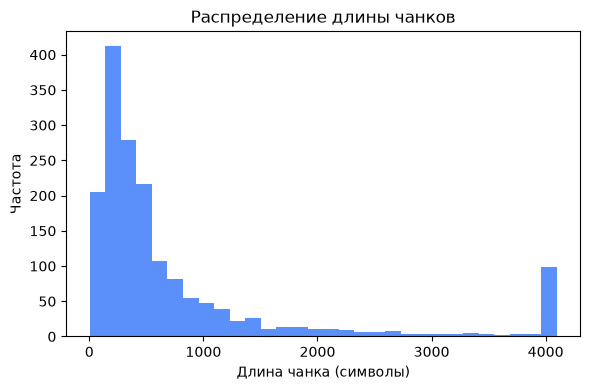

,doc_id,chunk_id,title,doc_type,docdate,text_preview
0,605242917,605242917_chunk_0,"О Федеральном законе ""О внесении изменений в с...",Постановление,22.03.2023,ПОСТАНОВЛЕНИЕ ГОСУДАРСТВЕННОЙ ДУМЫ ФЕДЕРАЛЬН...
1,605242917,605242917_chunk_1,"О Федеральном законе ""О внесении изменений в с...",Постановление,22.03.2023,"1. Принять Федеральный закон ""О внесении измен..."
2,605242917,605242917_chunk_2,"О Федеральном законе ""О внесении изменений в с...",Постановление,22.03.2023,2. Направить указанный Федеральный закон в Сов...


In [4]:
subset_docs = documents[:N_DOCS]
start = time.time()
chunks = chunk_documents(
    subset_docs,
    chunk_size_chars=CHUNK_SIZE_CHARS,
    overlap_chars=OVERLAP_CHARS,
)
elapsed = time.time() - start
print(f"Чанков: {len(chunks)} из {len(subset_docs)} документов, время: {elapsed:.2f}s")

lengths = [len(c.text) for c in chunks]
print({
    "min": int(np.min(lengths)) if lengths else 0,
    "p50": int(np.median(lengths)) if lengths else 0,
    "p90": int(np.percentile(lengths, 90)) if lengths else 0,
    "max": int(np.max(lengths)) if lengths else 0,
})

plt.figure(figsize=(6,4))
plt.hist(lengths, bins=30, color="#5b8ff9")
plt.xlabel("Длина чанка (символы)")
plt.ylabel("Частота")
plt.title("Распределение длины чанков")
plt.tight_layout()
plt.show()

example_rows = []
for ch in islice(chunks, 3):
    example_rows.append({
        "doc_id": ch.doc_id,
        "chunk_id": ch.chunk_id,
        "title": ch.metadata.get("title"),
        "doc_type": ch.metadata.get("doc_type") or ch.metadata.get("doc_typeIPS"),
        "docdate": ch.metadata.get("docdate") or ch.metadata.get("docdateIPS"),
        "text_preview": ch.text[:200].replace("\n", " ") + "...",
    })
display(pd.DataFrame(example_rows).fillna("—").replace("", "—"))


## 3. Построение индексов <a id='3-index'></a>
Строим BM25 и, при доступной модели, Dense/Hybrid. Если модель не найдена локально и скачивание запрещено, выводим предупреждение.


In [5]:
# BM25 доступен и при ошибке загрузки модели или построения Dense.
retrievers = build_retrievers(chunks, use_dense=False, use_hybrid=False)
retriever_errors = {}

use_dense = any(r in {"dense", "hybrid"} for r in RETRIEVERS_TO_BUILD)
embedder = None
if use_dense:
    try:
        embedder = SentenceTransformerEmbeddings(
            model_name=EMBEDDING_MODEL,
            batch_size=EMBEDDING_BATCH_SIZE,
        )
        retrievers.update(build_retrievers(
            chunks,
            use_dense=True,
            use_hybrid="hybrid" in RETRIEVERS_TO_BUILD,
            embedder=embedder,
            min_chunk_chars=MIN_CHUNK_CHARS,
        ))
    except Exception as exc:
        retriever_errors["dense"] = str(exc)
        print(f"Dense/Hybrid недоступны: {exc}. Продолжаем с BM25.")

print(f"Построены retrievers: {list(retrievers.keys())}")


2026-11-05 17:43:45 | INFO | rag.index.bm25 | Строим BM25 индекс по 1707 чанкам
2026-11-05 17:43:45 | INFO | rag.index.bm25 | Строим BM25 индекс по 1707 чанкам
2026-11-05 17:43:45 | INFO | rag.index.faiss_dense | Строим FAISS индекс по 1673 чанкам (min_len=50)
2026-11-05 17:43:45 | INFO | rag.embeddings.st | Загрузка модели эмбеддингов: intfloat/multilingual-e5-small (cache=/home/bibeda/psb-rag/data/cache/embeddings)
2026-11-05 17:43:45 | INFO | sentence_transformers.base.model | Loading SentenceTransformer model from intfloat/multilingual-e5-small.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7499.79it/s]
2026-11-05 17:45:35 | INFO | rag.index.faiss_dense | FAISS индекс построен: dim=384, vectors=1673, time=110.21s
2026-11-05 17:45:35 | INFO | rag.cli.retrieve_cli | Dense retriever: embedder=SentenceTransformerEmbeddings, dim=384


Построены retrievers: ['bm25', 'dense', 'hybrid']


## 4. Retrieval демо <a id='4-retrieval'></a>
Выберем запрос из примеров и сравним top-k для каждого доступного retriever.


In [6]:

QUERY = QUERY_EXAMPLES[0]
print(f"Запрос: {QUERY}")

def summarize_results(results: list[RetrievedChunk]):
    unique_docs = len({r.doc_id for r in results}) if results else 0
    coverage = unique_docs / len(results) if results else 0
    from collections import Counter
    doc_counts = Counter(r.doc_id for r in results)
    dominance = (max(doc_counts.values()) / len(results)) if results else 0
    return unique_docs, coverage, dominance

for name, retr in retrievers.items():
    res = retr.retrieve(QUERY, k=K)
    unique_docs, coverage, dominance = summarize_results(res)
    print(f"\n{name.upper()} — найдено {len(res)}, уникальных doc_id: {unique_docs}, coverage={coverage:.2f}, dominance={dominance:.2f}")
    rows = []
    for r in res:
        rows.append({
            "doc_id": r.doc_id,
            "chunk_id": r.chunk_id,
            "score": r.score,
            "doc_type": r.metadata.get("doc_type") or r.metadata.get("doc_typeIPS"),
            "docdate": r.metadata.get("docdate") or r.metadata.get("docdateIPS"),
            "title": r.metadata.get("title") or r.metadata.get("heading") or r.metadata.get("headingIPS"),
            "text_preview": (r.text or "")[:240].replace("\n", " ") + "...",
        })
    display(pd.DataFrame(rows).fillna("—").replace("", "—"))


Запрос: налог на доходы физических лиц

BM25 — найдено 10, уникальных doc_id: 6, coverage=0.60, dominance=0.30


,doc_id,chunk_id,score,doc_type,docdate,title,text_preview
0,102052518,102052518_chunk_4,11.726281,Постановление,16.04.1998,О проекте Налогового кодекса Российской Федерации,"4. Комитету Государственной Думы по бюджету, н..."
1,102145716,102145716_chunk_7,8.404572,Приказ,02.12.2010,Об утверждении Порядка составления и утвержден...,5. В Плане указываются: цели деятельности уч...
2,102034845,102034845_chunk_0,8.183495,Постановление,27.03.1995,О цене на природный газ,ПРАВИТЕЛЬСТВО РОССИЙСКОЙ ФЕДЕРАЦИИ Постановл...
3,102145716,102145716_chunk_13,8.084890,Приказ,02.12.2010,Об утверждении Порядка составления и утвержден...,"11. Объемы планируемых выплат, источником фина..."
4,603612081,603612081_chunk_9,7.660747,Приказ,11.11.2022,Об утверждении федерального государственного о...,"единения, иных юридических и (или) физических ..."
5,102145716,102145716_chunk_8,7.655203,Приказ,02.12.2010,Об утверждении Порядка составления и утвержден...,6. Плановые показатели по поступлениям формиру...
6,602400066,602400066_chunk_6,6.740148,Приказ,31.03.2021,Об определении Порядка информационного взаимод...,6. При организации информационного взаимодейст...
7,102026299,102026299_chunk_89,5.955598,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,1. Консульские должностные лица и консульские ...
8,602400066,602400066_chunk_19,5.106969,Приказ,31.03.2021,Об определении Порядка информационного взаимод...,19. Территориальный фонд обеспечивает предоста...
9,102026299,102026299_chunk_41,4.669975,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,2. Государство пребывания относится к консульс...



DENSE — найдено 10, уникальных doc_id: 6, coverage=0.60, dominance=0.30


,doc_id,chunk_id,score,doc_type,docdate,title,text_preview
0,102091553,102091553_chunk_3,0.852318,Постановление,21.03.2005,О порядке заключения соглашений между Министер...,"1. Настоящие Правила регулируют отношения, свя..."
1,102026299,102026299_chunk_89,0.847270,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,1. Консульские должностные лица и консульские ...
2,102026299,102026299_chunk_54,0.844877,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,"2. Налоговые изъятия, указанные в пункте 1 нас..."
3,102026299,102026299_chunk_91,0.844020,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,"3. Работники консульского учреждения, нанимающ..."
4,102134851,102134851_chunk_13,0.842743,Приказ,21.09.2009,Об обязательном государственном страховании жи...,7. В соответствии с пунктом 4 статьи 2 Федерал...
5,102078483,102078483_chunk_1,0.841451,Постановление,24.10.2002,"О проекте федерального закона N 68161-3 ""О вне...",1. Принять в первом чтении проект федерального...
6,102091553,102091553_chunk_11,0.840684,Постановление,21.03.2005,О порядке заключения соглашений между Министер...,9. В случае невыполнения предусмотренных в сог...
7,102078483,102078483_chunk_0,0.838129,Постановление,24.10.2002,"О проекте федерального закона N 68161-3 ""О вне...",ПОСТАНОВЛЕНИЕ ГОСУДАРСТВЕННОЙ ДУМЫ ФЕДЕРАЛЬН...
8,102052518,102052518_chunk_1,0.835216,Постановление,16.04.1998,О проекте Налогового кодекса Российской Федерации,1. Принять в первом чтении проект Налогового к...
9,102145716,102145716_chunk_5,0.834367,Приказ,02.12.2010,Об утверждении Порядка составления и утвержден...,3. План составляется на финансовый год в случа...


2026-11-05 17:45:35 | INFO | rag.index.hybrid | Hybrid retrieve: query='налог на доходы физических лиц', bm25=20, dense=20



HYBRID — найдено 10, уникальных doc_id: 7, coverage=0.70, dominance=0.30


,doc_id,chunk_id,score,doc_type,docdate,title,text_preview
0,102026299,102026299_chunk_89,5.955598,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,1. Консульские должностные лица и консульские ...
1,102052518,102052518_chunk_4,11.726281,Постановление,16.04.1998,О проекте Налогового кодекса Российской Федерации,"4. Комитету Государственной Думы по бюджету, н..."
2,102091553,102091553_chunk_3,0.852318,Постановление,21.03.2005,О порядке заключения соглашений между Министер...,"1. Настоящие Правила регулируют отношения, свя..."
3,102145716,102145716_chunk_7,8.404572,Приказ,02.12.2010,Об утверждении Порядка составления и утвержден...,5. В Плане указываются: цели деятельности уч...
4,102034845,102034845_chunk_0,8.183495,Постановление,27.03.1995,О цене на природный газ,ПРАВИТЕЛЬСТВО РОССИЙСКОЙ ФЕДЕРАЦИИ Постановл...
5,102026299,102026299_chunk_54,0.844877,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,"2. Налоговые изъятия, указанные в пункте 1 нас..."
6,102145716,102145716_chunk_13,8.084890,Приказ,02.12.2010,Об утверждении Порядка составления и утвержден...,"11. Объемы планируемых выплат, источником фина..."
7,102026299,102026299_chunk_91,4.132580,Распоряжение,25.09.1993,О подписании Консульской конвенции между Росси...,"3. Работники консульского учреждения, нанимающ..."
8,603612081,603612081_chunk_9,7.660747,Приказ,11.11.2022,Об утверждении федерального государственного о...,"единения, иных юридических и (или) физических ..."
9,102134851,102134851_chunk_13,0.842743,Приказ,21.09.2009,Об обязательном государственном страховании жи...,7. В соответствии с пунктом 4 статьи 2 Федерал...


### Подробный обзор

In [ ]:
def show_retrieved_chunks(name, query):
    if name not in retrievers:
        print(f"{name.upper()} недоступен: {retriever_errors.get('dense', 'индекс не построен')}")
        return
    print(query)
    print()
    retriever = retrievers[name]
    res = retriever.retrieve(query, k=K)
    for r in res:
        print(f"doc_id={r.doc_id}, title={r.metadata.get('title')}")
        print(f"{r.text}")
        print()

In [ ]:
show_retrieved_chunks('bm25', QUERY)

In [ ]:
show_retrieved_chunks('dense', QUERY)

In [ ]:
show_retrieved_chunks('hybrid', QUERY)